# 0. Some technical steps

In this notebook we work with daily historical sales data. Our dataset consists of the following columns:

1) shop_id - unique identifier of a shop
2) item_id - unique identifier of a product
3) item_category_id - unique identifier of item category
4) item_cnt_day - number of products sold. We are predicting a monthly amount of this measure
5) item_price - current price of an item
6) date - date in format dd/mm/yyyy
7) date_block_num - a consecutive month number, used for convenience. January 2013 is 0, February 2013 is 1,..., October 2015 is 33
8) item_name - name of item
9) shop_name - name of shop
10) item_category_name - name of item category

In [1]:
import pandas as pd

train = pd.read_csv("data/sales_train.csv")
train

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.0
1,03.01.2013,0,25,2552,899.00,1.0
2,05.01.2013,0,25,2552,899.00,-1.0
3,06.01.2013,0,25,2554,1709.05,1.0
4,15.01.2013,0,25,2555,1099.00,1.0
...,...,...,...,...,...,...
2935844,10.10.2015,33,25,7409,299.00,1.0
2935845,09.10.2015,33,25,7460,299.00,1.0
2935846,14.10.2015,33,25,7459,349.00,1.0
2935847,22.10.2015,33,25,7440,299.00,1.0


In [2]:
items = pd.read_csv("data/items.csv")
items

,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40
...,...,...,...
22165,"Ядерный титбит 2 [PC, Цифровая версия]",22165,31
22166,Язык запросов 1С:Предприятия [Цифровая версия],22166,54
22167,Язык запросов 1С:Предприятия 8 (+CD). Хрустале...,22167,49
22168,Яйцо для Little Inu,22168,62


In [3]:
shops = pd.read_csv("data/shops.csv")
shops

,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4
5,"Вологда ТРЦ ""Мармелад""",5
6,"Воронеж (Плехановская, 13)",6
7,"Воронеж ТРЦ ""Максимир""",7
8,"Воронеж ТРЦ Сити-Парк ""Град""",8
9,Выездная Торговля,9


In [4]:
categories = pd.read_csv("data/item_categories.csv")
categories

,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4
...,...,...
79,Служебные,79
80,Служебные - Билеты,80
81,Чистые носители (шпиль),81
82,Чистые носители (штучные),82


In [5]:
result = pd.merge(train, shops, how="left", on=["shop_id"])
result = pd.merge(result, items, how="left", on=["item_id"])
train_result = pd.merge(result, categories, how="left", on=["item_category_id"])
train_result

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,shop_name,item_name,item_category_id,item_category_name
0,02.01.2013,0,59,22154,999.00,1.0,"Ярославль ТЦ ""Альтаир""",ЯВЛЕНИЕ 2012 (BD),37,Кино - Blu-Ray
1,03.01.2013,0,25,2552,899.00,1.0,"Москва ТРК ""Атриум""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
2,05.01.2013,0,25,2552,899.00,-1.0,"Москва ТРК ""Атриум""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
3,06.01.2013,0,25,2554,1709.05,1.0,"Москва ТРК ""Атриум""",DEEP PURPLE Who Do You Think We Are LP,58,Музыка - Винил
4,15.01.2013,0,25,2555,1099.00,1.0,"Москва ТРК ""Атриум""",DEEP PURPLE 30 Very Best Of 2CD (Фирм.),56,Музыка - CD фирменного производства
...,...,...,...,...,...,...,...,...,...,...
2935844,10.10.2015,33,25,7409,299.00,1.0,"Москва ТРК ""Атриум""",V/A Nu Jazz Selection (digipack),55,Музыка - CD локального производства
2935845,09.10.2015,33,25,7460,299.00,1.0,"Москва ТРК ""Атриум""",V/A The Golden Jazz Collection 1 2CD,55,Музыка - CD локального производства
2935846,14.10.2015,33,25,7459,349.00,1.0,"Москва ТРК ""Атриум""",V/A The Best Of The 3 Tenors,55,Музыка - CD локального производства
2935847,22.10.2015,33,25,7440,299.00,1.0,"Москва ТРК ""Атриум""",V/A Relax Collection Planet MP3 (mp3-CD) (jewel),57,Музыка - MP3


In [6]:
train_result.info()

<class 'pandas.DataFrame'>
RangeIndex: 2935849 entries, 0 to 2935848
Data columns (total 10 columns):
 #   Column              Dtype  
---  ------              -----  
 0   date                str    
 1   date_block_num      int64  
 2   shop_id             int64  
 3   item_id             int64  
 4   item_price          float64
 5   item_cnt_day        float64
 6   shop_name           str    
 7   item_name           str    
 8   item_category_id    int64  
 9   item_category_name  str    
dtypes: float64(2), int64(4), str(4)
memory usage: 224.0 MB


In [7]:
train_result.describe().round(2)

,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_category_id
count,2935849.00,2935849.00,2935849.00,2935849.00,2935849.00,2935849.0
mean,14.57,33.00,10197.23,890.85,1.24,40.0
std,9.42,16.23,6324.30,1729.80,2.62,17.1
min,0.00,0.00,0.00,-1.00,-22.00,0.0
25%,7.00,22.00,4476.00,249.00,1.00,28.0
50%,14.00,31.00,9343.00,399.00,1.00,40.0
75%,23.00,47.00,15684.00,999.00,1.00,55.0
max,33.00,59.00,22169.00,307980.00,2169.00,83.0


I guess it's impossible to get a negative price or negative item_cnt_day (number of product sold). Therefore these a possible missing values

# 1. Missing values

In [8]:
features_with_na = [
    features
    for features in train_result.columns
    if train_result[features].isnull().sum() > 1
]
features_with_na

[]

No missing values. But let's look into negative values in item_price and item_cnt_day

In [9]:
train_result[train_result["item_price"] < 0]

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,shop_name,item_name,item_category_id,item_category_name
484683,15.05.2013,4,32,2973,-1.0,1.0,"Москва ТЦ ""Серебряный Дом""","DmC Devil May Cry [PS3, русские субтитры]",19,Игры - PS3


In [10]:
print(train_result[train_result["item_cnt_day"] < 0].shape)
print(
    train_result[train_result["item_cnt_day"] < 0].shape[0]
    / train_result.shape[0]
    * 100
)

(7356, 10)
0.2505578454477734


7356 missing values are founded, we'll drop them later at data cleaning step

# 2. Numerical variables

## 2.1 Statistics

In [11]:
# Numeric columns only; drop ID-like columns that are really categorical
num = train_result.select_dtypes("number").drop(
    columns=["shop_id", "item_id", "item_category_id"]
)

stats = num.agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).T
stats = stats.join(num.quantile([0.01, 0.25, 0.75, 0.99]).T.add_prefix("q"))
stats["negative"] = (num < 0).sum()

stats.style.format("{:,.2f}")

,count,mean,median,std,min,max,skew,kurt,q0.01,q0.25,q0.75,q0.99,negative
date_block_num,"2,935,849.00",14.57,14.00,9.42,0.00,33.00,0.20,-1.08,0.00,7.00,23.00,33.00,0.00
item_price,"2,935,849.00",890.85,399.00,"1,729.80",-1.00,"307,980.00",10.75,445.53,5.00,249.00,999.00,"5,999.00",1.00
item_cnt_day,"2,935,849.00",1.24,1.00,2.62,-22.00,"2,169.00",272.83,"177,478.10",1.00,1.00,1.00,5.00,"7,356.00"


item_price and especially item_cnt_day are extremely right-skewed with heavy outliers. These variables should be cleaned (drop the invalid price, clip or remove outliers) before modeling.

## 2.2 Seasonal-Trend decomposition 


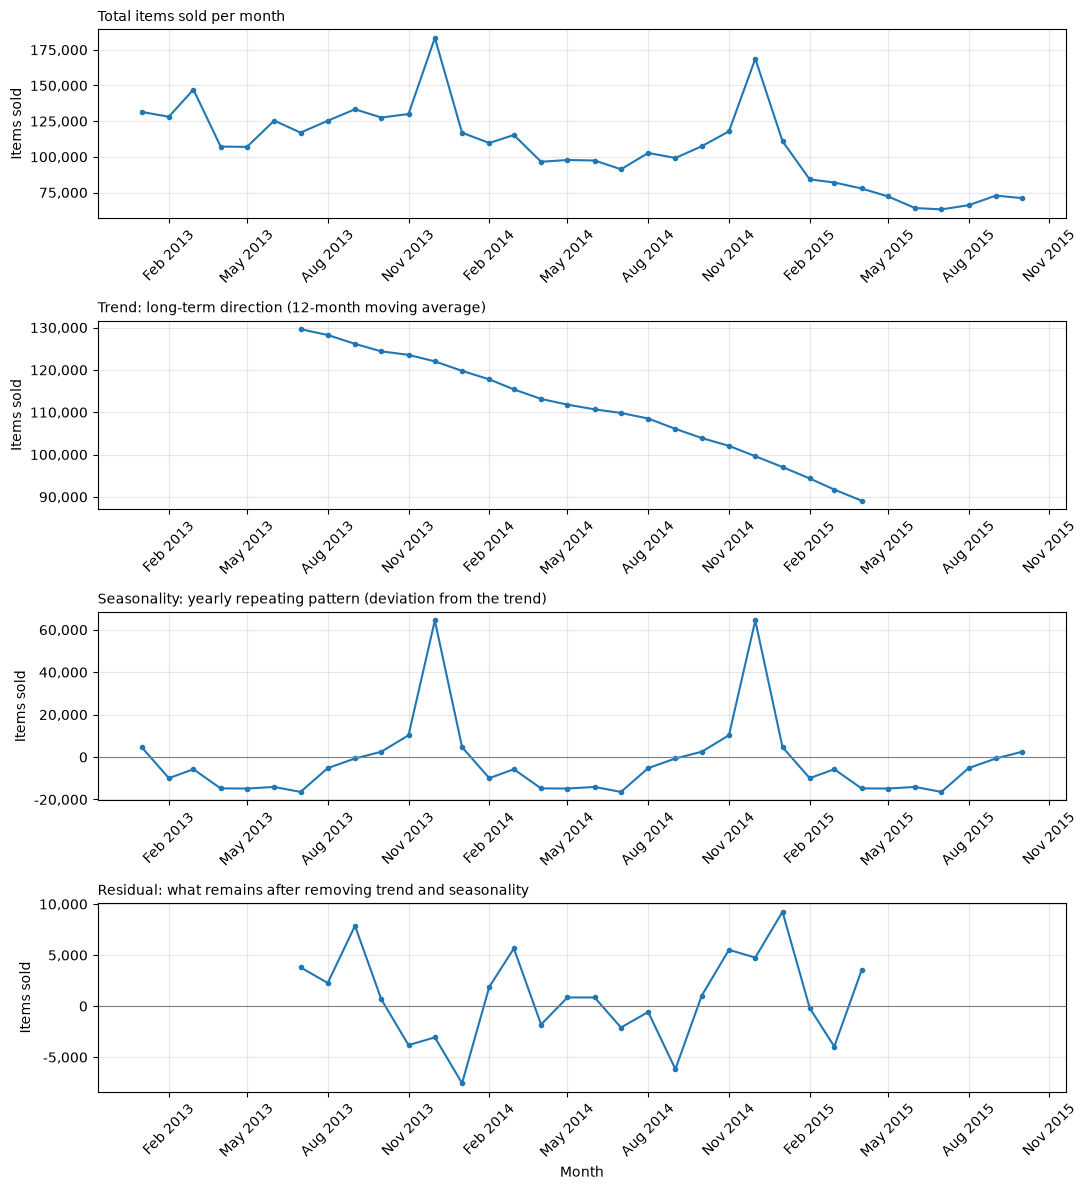

In [27]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Total items sold per month, indexed by real dates (block 0 = January 2013)
monthly = train_result.groupby("date_block_num")["item_cnt_day"].sum()
monthly.index = pd.date_range("2013-01-01", periods=len(monthly), freq="MS")

res = seasonal_decompose(monthly, model="additive", period=12)

panels = [
    (res.observed, "Total items sold per month"),
    (res.trend, "Trend: long-term direction (12-month moving average)"),
    (res.seasonal, "Seasonality: yearly repeating pattern (deviation from the trend)"),
    (res.resid, "Residual: what remains after removing trend and seasonality"),
]

fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
for ax, (series, title) in zip(axes, panels):
    ax.plot(series, marker="o", markersize=3)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_ylabel("Items sold")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
    ax.grid(alpha=0.3)

    # sharex hides tick labels on all but the bottom axis: turn them back on
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45)

# Zero reference line where values are deviations, not absolute levels
axes[2].axhline(0, color="gray", lw=0.8)
axes[3].axhline(0, color="gray", lw=0.8)
axes[-1].set_xlabel("Month")

plt.tight_layout()
plt.show()

First, we see a gradually declining trend. Secondly, the highest peak of sales is in December (because of the New Year) with a small peak after (maybe because of 8th of March). Residuals are clearly noise as was expected

## 2.3 Correlation analysis

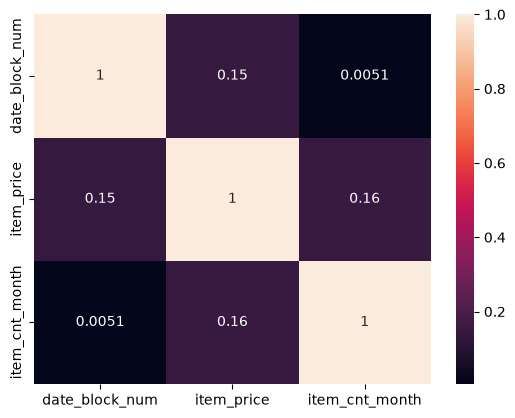

In [33]:
# Monthly target per (month, shop, item): this is what the competition predicts
df = train_result.groupby(["date_block_num", "shop_id", "item_id"], as_index=False).agg(
    item_cnt_month=("item_cnt_day", "sum"),
    item_price=("item_price", "mean"),
    item_category_id=("item_category_id", "first"),
)
df["year"] = 2013 + df["date_block_num"] // 12
df["month"] = df["date_block_num"] % 12 + 1
target = "item_cnt_month"

import seaborn as sns

# Spearman is robust to the heavy skew; IDs are excluded on purpose
sns.heatmap(
    df[["date_block_num", "item_price", target]].corr(method="spearman"), annot=True
)
plt.show()

There is no strong correlation between the numeric features. A weak correlation does not make the features useless: the dependence on time is non-monotonic (seasonality) and is not captured by Spearman correlation.

# 3. Distribution of Numerical Variables

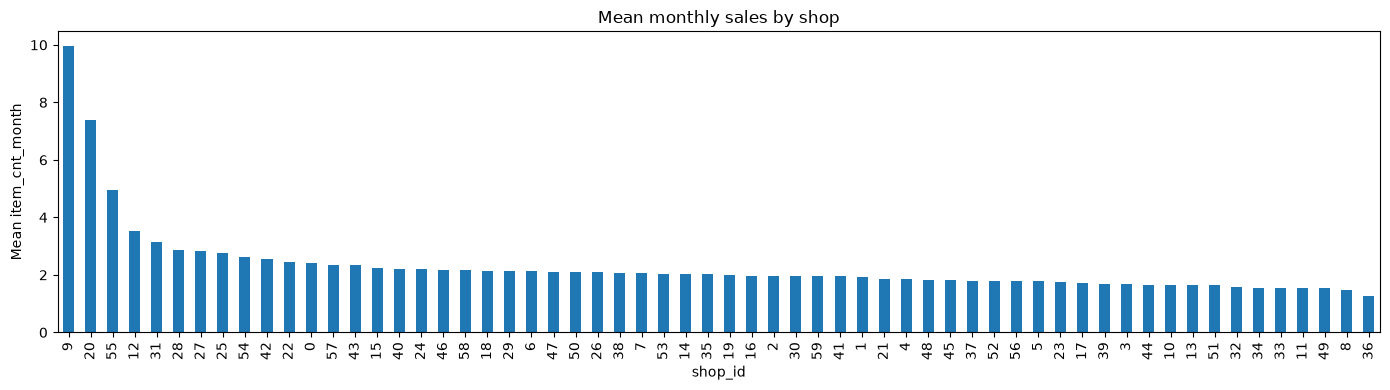

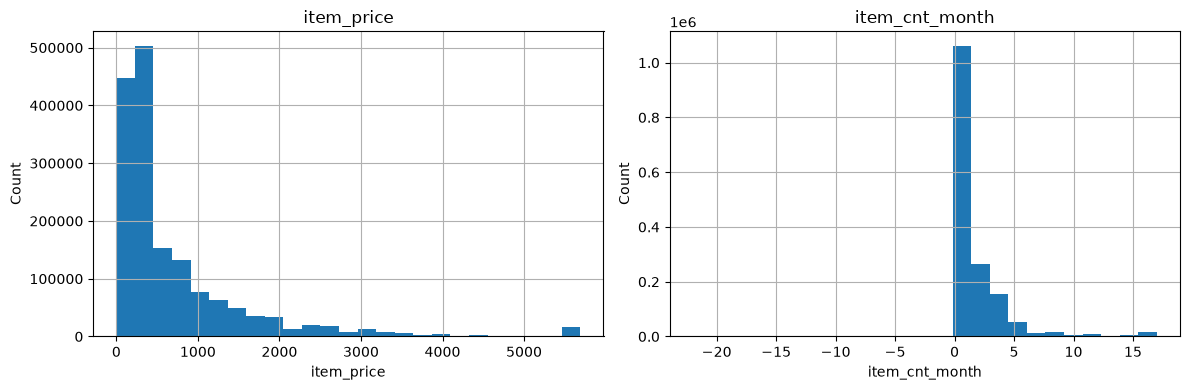

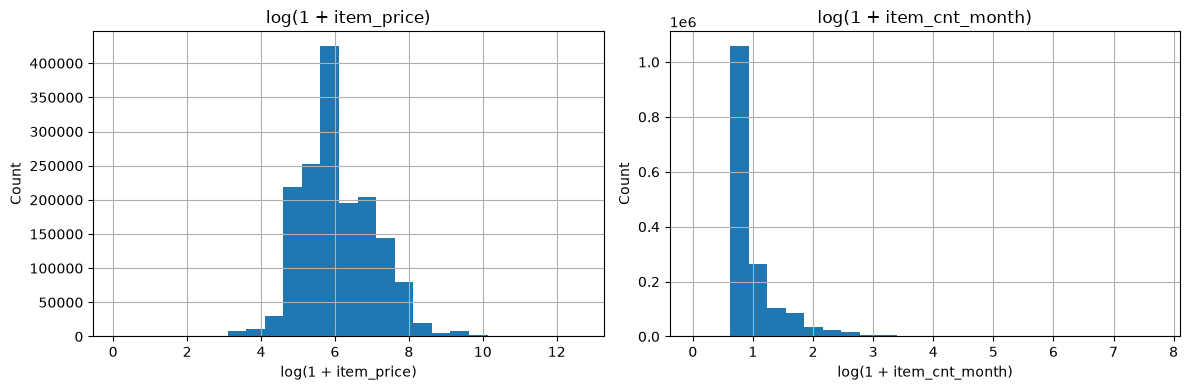

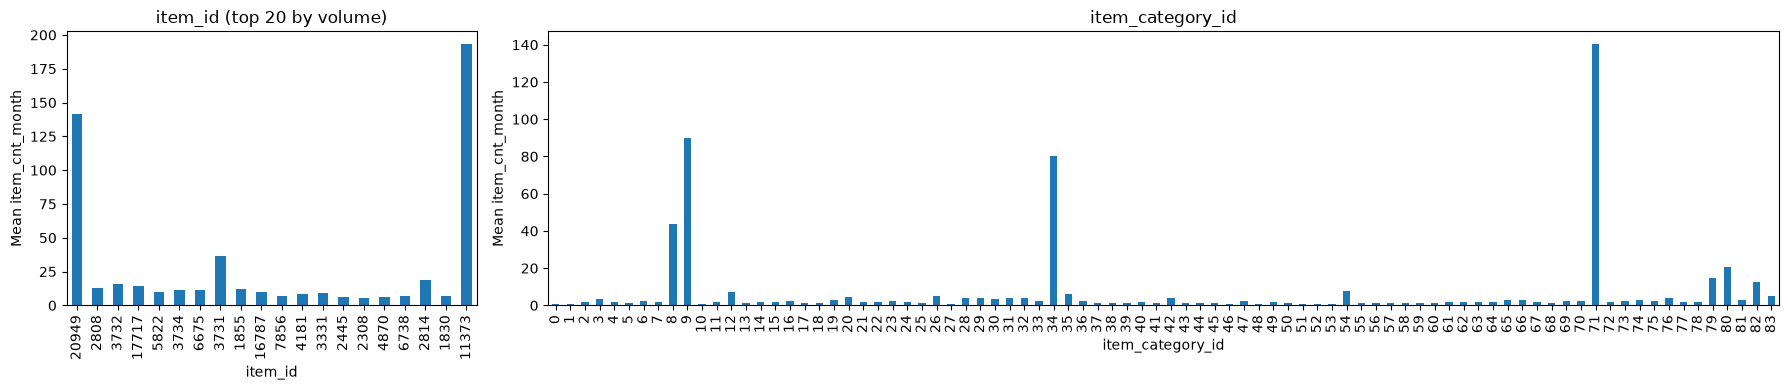

In [32]:
import numpy as np

# Shop vs target
plt.figure(figsize=(14, 4))
df.groupby("shop_id")[target].mean().sort_values(ascending=False).plot.bar()
plt.xlabel("shop_id")
plt.ylabel(f"Mean {target}")
plt.title("Mean monthly sales by shop")
plt.tight_layout()
plt.show()

# Continuous features: histograms (clipped at the 99th percentile for readability)
continuous_feature = ["item_price", target]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, continuous_feature):
    df[feature].clip(upper=df[feature].quantile(0.99)).hist(bins=25, ax=ax)
    ax.set(title=feature, xlabel=feature, ylabel="Count")
plt.tight_layout()
plt.show()

# Log-transformed continuous features: histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, continuous_feature):
    # clip(lower=0) guards against the rare negative price; log1p(0) = 0 is safe
    np.log1p(df[feature].clip(lower=0)).hist(bins=25, ax=ax)
    ax.set(title=f"log(1 + {feature})", xlabel=f"log(1 + {feature})", ylabel="Count")
plt.tight_layout()
plt.show()

# Mean monthly sales per item and per category (same style as the first plot)
fig, axes = plt.subplots(1, 2, figsize=(18, 4), gridspec_kw={"width_ratios": [1, 3]})

# Items: ~22k of them, so show only the 20 best-selling ones (by total volume)
top_items = df.groupby("item_id")[target].agg(["sum", "mean"]).nlargest(20, "sum")
top_items["mean"].plot.bar(ax=axes[0])
axes[0].set(
    title="item_id (top 20 by volume)", xlabel="item_id", ylabel=f"Mean {target}"
)

# Categories: all of them
df.groupby("item_category_id")[target].mean().plot.bar(ax=axes[1])
axes[1].set(
    title="item_category_id", xlabel="item_category_id", ylabel=f"Mean {target}"
)

plt.tight_layout()
plt.show()

- Sales across the stores are more or less the same, though some stores (specifically 9, 20, and 55) are more popular and see higher sales

- `item_price` and `item_cnt_month` are primarily concentrated at low values but exhibit long, positive-skewed tails. A log transformation helps achieve a normal distribution for prices, but for the monthly sales quantity, this transformation is ineffective

- Even among the 20 best-selling items, mean monthly sales per (shop, month) are mostly 5–15 units; a few items (e.g. 11373 and 20949) are extreme outliers. They should be clipped or treated separately before modeling

- Most categories have mean monthly sales of 1–5 units, but a few (e.g. 71, 9, 34, 8) are far higher possibly because a few single items in them sell in very large amounts

## 3.1 Dead columns and data volume over time analysis

,n_unique,top_value,top_value_share
column,,,
date,1034,28.12.2013,0.3%
date_block_num,34,11,4.9%
item_price,19993,299.000000,9.9%
item_cnt_day,198,1.000000,89.6%
shop_name,60,"Москва ТЦ ""Семеновский""",8.0%
item_name,21807,Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,1.1%
item_category_name,84,Кино - DVD,19.2%


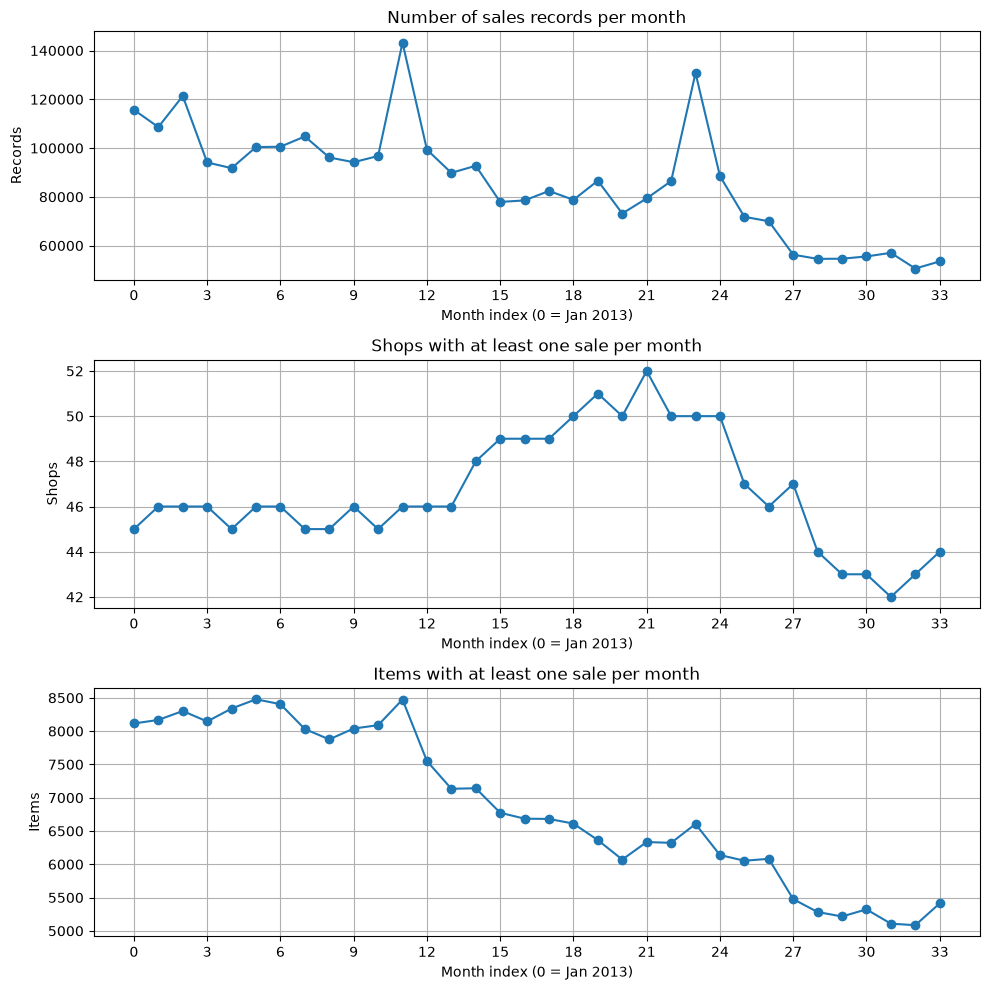

In [37]:
# 1. Dead / near-constant columns: unique values, most frequent value and its share
id_cols = ["shop_id", "item_id", "item_category_id"]

rows = []
for c in train_result.columns.drop(id_cols):
    counts = train_result[c].value_counts(
        normalize=True
    )  # sorted from most to least frequent
    rows.append(
        {
            "column": c,
            "n_unique": len(counts),
            "top_value": counts.index[0],
            "top_value_share": counts.iloc[0],
        }
    )
summary = pd.DataFrame(rows).set_index("column")
display(summary.style.format({"top_value_share": "{:.1%}"}))

# 2. Data volume per month: rows, active shops, active items
volume = train_result.groupby("date_block_num").agg(
    rows=("item_id", "size"),
    active_shops=("shop_id", "nunique"),
    active_items=("item_id", "nunique"),
)

panels = [
    ("rows", "Number of sales records per month", "Records"),
    ("active_shops", "Shops with at least one sale per month", "Shops"),
    ("active_items", "Items with at least one sale per month", "Items"),
]

fig, axes = plt.subplots(3, 1, figsize=(10, 10))
for ax, (col, title, ylabel) in zip(axes, panels):
    ax.plot(volume.index, volume[col], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Month index (0 = Jan 2013)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(0, len(volume), 3))
    ax.grid(True)
plt.tight_layout()
plt.show()

About 90% of `item_cnt_day` values equal 1, so the target is concentrated on small values; no column is constant and no other column has a dominant value. Over time, the number of sales records halves (with December peaks), active items fall from ~8,100 to ~5,400, and active shops vary between 42 and 52. The data is not stationary, so a time-based validation split is needed.

# 4. Outliers

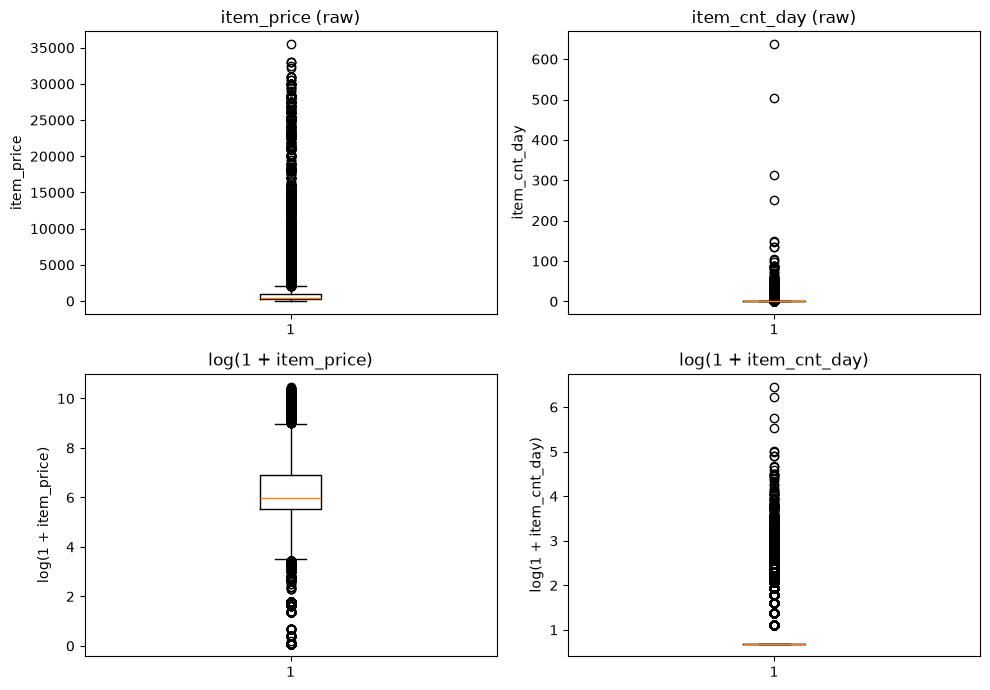

In [47]:
import numpy as np

continuous_feature = ["item_price", "item_cnt_day"]

# boxplots
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for col, feature in enumerate(continuous_feature):
    # log needs positive values; sample to keep the plot fast (2.9M rows)
    data = train_result.loc[train_result[feature] > 0, feature]
    sample = data.sample(200_000, random_state=42)

    axes[0, col].boxplot(sample)
    axes[0, col].set(title=f"{feature} (raw)", ylabel=feature)

    axes[1, col].boxplot(np.log1p(sample))
    axes[1, col].set(title=f"log(1 + {feature})", ylabel=f"log(1 + {feature})")
plt.tight_layout()
plt.show()


# Statistical detection
def outlier_report(series, feature):
    s = series.dropna()

    # IQR: outside [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_low, iqr_high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    # Z-score: more than 3 standard deviations away from the mean
    z_low, z_high = s.mean() - 3 * s.std(), s.mean() + 3 * s.std()

    rows = [
        ("IQR", iqr_low, iqr_high, ((s < iqr_low) | (s > iqr_high)).sum()),
        ("Z-score", z_low, z_high, ((s < z_low) | (s > z_high)).sum()),
    ]
    out = pd.DataFrame(
        rows, columns=["Method", "Lower bound", "Upper bound", "Outliers (count)"]
    )
    out["Outliers (share)"] = out["Outliers (count)"] / len(s)
    out.insert(0, "Feature", feature)
    return out


report = pd.concat(
    [outlier_report(train_result[f], f) for f in continuous_feature]
).set_index(["Feature", "Method"])

display(
    report.style.format(
        {
            "Lower bound": "{:,.1f}",
            "Upper bound": "{:,.1f}",
            "Outliers (count)": "{:,.0f}",
            "Outliers (share)": "{:.1%}",
        }
    )
)

The IQR flags 8.8% of `item_price` values and the Z-score only 1.0%, because the distribution is right-skewed: IQR labels part of the natural tail as outliers, while extreme values inflate the standard deviation.For item_cnt_day the IQR rule does not work properly: most values equal 1, so the IQR is 0 and every other value is flagged as an outlier. So the Z-score is more informative. Extreme outliers will be dropped before modeling part.

# 5. Categorical Variables

## 5.1 Cardinality check

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

# Categorical features: text columns + ID columns (numeric, but categorical by meaning)
id_cols = ["shop_id", "item_id", "item_category_id"]
categorical_features = (
    train_result.select_dtypes("object").columns.drop("date").tolist() + id_cols
)

# Cardinality: number of categories and share of the most frequent one
cardinality = pd.DataFrame(
    {
        "n_categories": train_result[categorical_features].nunique(),
        "top_category_share": [
            train_result[f].value_counts(normalize=True).iloc[0]
            for f in categorical_features
        ],
    }
).sort_values("n_categories")
cardinality.style.format({"top_category_share": "{:.1%}"})

C:\Users\pikil\AppData\Local\Temp\ipykernel_32580\2439633828.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_result.select_dtypes("object").columns.drop("date").tolist() + id_cols


,n_categories,top_category_share
shop_name,60,8.0%
shop_id,60,8.0%
item_category_name,84,19.2%
item_category_id,84,19.2%
item_name,21807,1.1%
item_id,21807,1.1%


Shops and item categories have low cardinality and can be encoded directly, while items have very high cardinality. No single category
dominate. Names and IDs have identical counts, so each name duplicates its ID and only one of them should be used as a feature.

## 5.2 Duplicates check

In [55]:
from difflib import SequenceMatcher
from itertools import combinations

import pandas as pd

# Keys of the reference tables must be unique, otherwise merges duplicate rows
refs = [
    ("shops", shops, "shop_id", "shop_name"),
    ("items", items, "item_id", "item_name"),
    ("categories", categories, "item_category_id", "item_category_name"),
]
for label, ref, id_col, name_col in refs:
    n_dup_ids = ref[id_col].duplicated().sum()
    n_dup_names = ref[name_col].str.lower().str.strip().duplicated().sum()
    print(
        f"{label}: duplicated IDs = {n_dup_ids}, exact duplicated names = {n_dup_names}"
    )

# Near-duplicate names under different IDs (candidates for manual review)
for label, ref, id_col, name_col, threshold in [
    ("shops", shops, "shop_id", "shop_name", 0.85),
    ("categories", categories, "item_category_id", "item_category_name", 0.9),
]:
    names = ref.set_index(id_col)[name_col]
    clean = names.str.lower().str.strip("! ")
    rows = []
    for a, b in combinations(names.index, 2):
        ratio = SequenceMatcher(None, clean[a], clean[b]).ratio()
        if ratio > threshold:
            rows.append((a, b, round(ratio, 2), names[a], names[b]))
    print(f"\nSimilar {label}:")
    display(
        pd.DataFrame(rows, columns=["id_a", "id_b", "similarity", "name_a", "name_b"])
    )

# date must agree with date_block_num (0 = January 2013)
dates = pd.to_datetime(train_result["date"], format="%d.%m.%Y")
expected_block = (dates.dt.year - 2013) * 12 + dates.dt.month - 1
print(
    "Rows where date and date_block_num disagree:",
    (expected_block != train_result["date_block_num"]).sum(),
)

shops: duplicated IDs = 0, exact duplicated names = 0
items: duplicated IDs = 0, exact duplicated names = 59
categories: duplicated IDs = 0, exact duplicated names = 0

Similar shops:


,id_a,id_b,similarity,name_a,name_b
0,0,57,0.90,"!Якутск Орджоникидзе, 56 фран","Якутск Орджоникидзе, 56"
1,1,58,0.90,"!Якутск ТЦ ""Центральный"" фран","Якутск ТЦ ""Центральный"""
2,10,11,0.96,Жуковский ул. Чкалова 39м?,Жуковский ул. Чкалова 39м²
3,23,24,0.94,"Москва ТК ""Буденовский"" (пав.А2)","Москва ТК ""Буденовский"" (пав.К7)"
4,39,40,0.88,"РостовНаДону ТРК ""Мегацентр Горизонт""","РостовНаДону ТРК ""Мегацентр Горизонт"" Островной"



Similar categories:


,id_a,id_b,similarity,name_a,name_b
0,1,2,0.94,Аксессуары - PS2,Аксессуары - PS3
1,1,3,0.94,Аксессуары - PS2,Аксессуары - PS4
2,1,4,0.94,Аксессуары - PS2,Аксессуары - PSP
3,2,3,0.94,Аксессуары - PS3,Аксессуары - PS4
4,2,4,0.94,Аксессуары - PS3,Аксессуары - PSP
5,3,4,0.94,Аксессуары - PS4,Аксессуары - PSP
6,10,11,0.95,Игровые консоли - PS2,Игровые консоли - PS3
7,10,12,0.95,Игровые консоли - PS2,Игровые консоли - PS4
8,10,13,0.95,Игровые консоли - PS2,Игровые консоли - PSP
9,11,12,0.95,Игровые консоли - PS3,Игровые консоли - PS4


Rows where date and date_block_num disagree: 0


In the results we found 59 exact duplicates of item names. We also found 3 pairs of duplicated shops (0/57, 1/58, 10/11) with the same address and a different franchise marker or typo, which will be merged. The other similar shop names (23/24, 39/40) are different pavilions or branches, and all similar category names differ by platform or format (PS2/PS3/PS4/PSP, Blu-Ray/3D/4K, MAC/PC), so there are no duplicated categories.

# Conclusion

**Macro patterns.** Total monthly sales decline steadily with a strong December peak each year. Part of the decline is structural: active items fell by one third and the number of active shops varied between 42 and 52. 

**Target modeling bottlenecks.** The target is a heavily right-skewed count dominated by small values (about 90% of daily records equal 1) with extreme outliers. It is also non-stationary (shrinking assortment, new items without history) and has high item cardinality. 

For the next step we'll:

- drop the invalid price (negative value) and extreme outliers for item price and sales
- clip the monthly target to [0, 20]
- apply a log transformation to item price
- merge duplicated shops and items
- use a time-based validation split